In [1]:
import astropy.units as u
import astropy.constants as const
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from tqdm.notebook import tqdm
import json
import h5py
import os

import warnings
warnings.filterwarnings("ignore")

from DiscEvolution.grid import Grid
from DiscEvolution.star import SimpleStar
from DiscEvolution.eos import LocallyIsothermalEOS  
from DiscEvolution.eos import SimpleDiscEOS
from DiscEvolution.eos import IrradiatedEOS  
from DiscEvolution.disc import AccretionDisc
from DiscEvolution.viscous_evolution import ViscousEvolutionFV
from DiscEvolution.driver import PlanetDiscDriver
from DiscEvolution.io import Event_Controller
from DiscEvolution.dust import DustGrowthTwoPop, SingleFluidDrift
from DiscEvolution.viscous_evolution import HybridWindModel
from DiscEvolution.opacity import Zhu2012
from DiscEvolution.constants import yr as yr_code, GasConst, Omega0, AU, Msun  # DiscEvolution uses code units: 1 year = 2π code time units
from DiscEvolution.chemistry import SimpleCOAtomAbund, EquilibriumCOChemOberg
from DiscEvolution import planet_formation as pf
from DiscEvolution.diffusion import TracerDiffusion 
from DiscEvolution.planet_formation import Planets, Bitsch2015Model
from DiscEvolution.constants import *

In [2]:
def h5_to_dict(h5obj):
    """Recursively load HDF5 file into nested dict."""
    out = {}
    for k, v in h5obj.items():
        if isinstance(v, h5py.Dataset):
            out[k] = v[()]  # load dataset into memory
        else:
            out[k] = h5_to_dict(v)  # recurse into group
    return out

# Define file paths with descriptive labels (not CR/XR/CX)
file_paths = {
    "IsaacTest" : "/Users/james/Documents/GitHub/DiscEvolution/james/october2026/output/Isaac/winds_mig_psi6.423e+00_Mdot1.0e-07_M1.0e-02_Rd5.0e+01_20261002_111533.h5", 
}

# Load all files into a single nested dictionary
datasets = {}
for label, path in file_paths.items():
    with h5py.File(path, "r") as f:
        datasets[label] = {
            "data": h5_to_dict(f),
            "attrs": dict(f.attrs),
        }

print(f"✓ Loaded {len(datasets)} simulations")
for label in datasets.keys():
    print(f"  {label}: {list(datasets[label]['data'].keys())}")

✓ Loaded 1 simulations
  IsaacTest: ['B_xe', 'C_xe', 'D_xe', 'H', 'JXR', 'Lambda', 'Mdot_r', 'NH', 'P', 'R', 'R_dz', 'R_dz_t', 'R_faces', 'Sigc', 'Sigma_G', 'Sigma_dust', 'Sigma_grain_size', 'Sigma_pebble_size', 'Sigma_pebbles', 'St', 'T', 'Tc', 'Vdrift', 'alpha_R', 'disk_Mass', 'disk_Mdot_star', 'disk_atom_gas_abund', 'disk_atom_ice_abund', 'disk_ice_lines', 'disk_mol_gas_abund', 'disk_mol_ice_abund', 'eta_diff', 'n_density', 'nu', 'psi_R', 'rho_mid', 'sigmaXR', 't', 'tau_XR', 'time_snap', 'v_r', 'xe', 'zeta', 'zeta_CR', 'zeta_XR']


In [3]:
dat = datasets["IsaacTest"]["data"]
for item in dat.keys():
   print(item)

B_xe
C_xe
D_xe
H
JXR
Lambda
Mdot_r
NH
P
R
R_dz
R_dz_t
R_faces
Sigc
Sigma_G
Sigma_dust
Sigma_grain_size
Sigma_pebble_size
Sigma_pebbles
St
T
Tc
Vdrift
alpha_R
disk_Mass
disk_Mdot_star
disk_atom_gas_abund
disk_atom_ice_abund
disk_ice_lines
disk_mol_gas_abund
disk_mol_ice_abund
eta_diff
n_density
nu
psi_R
rho_mid
sigmaXR
t
tau_XR
time_snap
v_r
xe
zeta
zeta_CR
zeta_XR


In [9]:
R = dat["R"]
L = dat["Lambda"]
t = dat["t"]
Rdz = dat['R_dz_t']
psi = dat['psi_R']

# Planets stuff
# Rp = dat['Rp']      # dict of planets radii
# Mcs = dat['Mcs']      # dict of planets cores
# Mes = dat['Mes']      # dict of planets enveloppes
# Mtot = { planet_id: Mcs[planet_id] + Mes[planet_id] for planet_id in Mcs }   # dict of planets total masses
# X_cores = dat["X_cores"]
# X_envs = dat["X_envs"]

# Disc Stuff 
Sigma_g = dat['Sigma_G']
Sigma_d = dat['Sigma_dust']
Sigma_peb = dat['Sigma_pebbles']
# Sigma_pmal = dat['Sigma_planetesimals']
tsnap = dat['time_snap']

# planet_ids = sorted(Rp.keys(), key=int)

In [15]:
planet_ids = np.empty((10,))
Rp = np.empty((10,))
Mcs = np.empty((10,))
Mes = np.empty((10,))
Mtot = np.empty((10,))
# X_cores = dat["X_cores"]
# X_envs = dat["X_envs"]

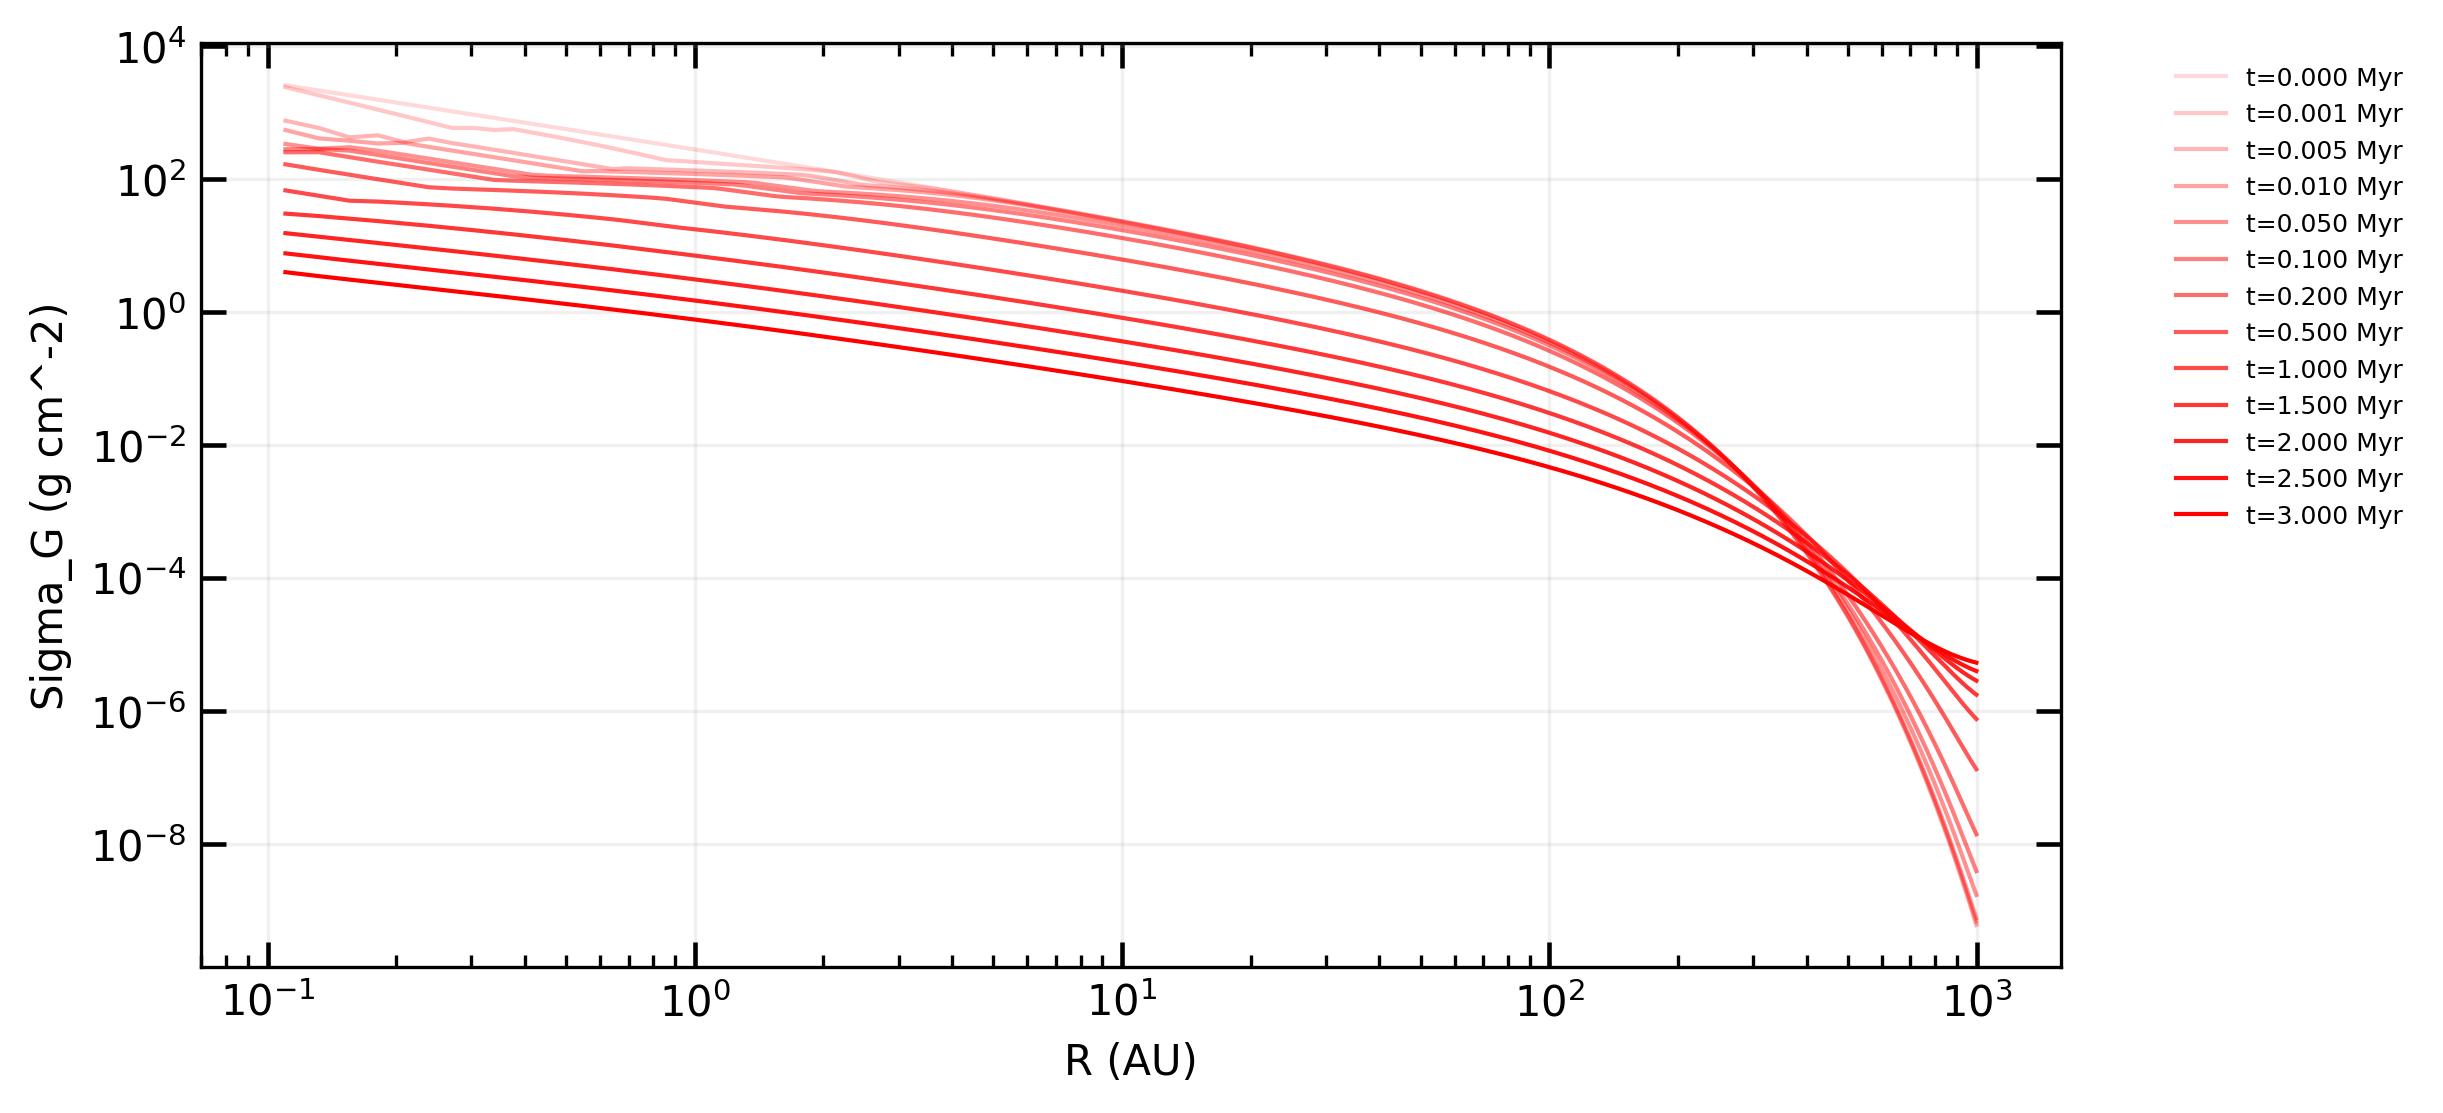

In [18]:
fig, ax = plt.subplots(figsize=(8, 4), dpi = 300)
alphas = np.array(np.linspace(0.15, 1.0, len(Sigma_g))) # ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.set_xlabel('R (AU)')
ax.set_ylabel('Sigma_G (g cm^-2)')
#ax.set_xlim(8,10)
# ax.set_ylim(1e-10,1e7)

for i in range(len(Sigma_g)):
    ax.loglog(
        R, Sigma_g[i],
        color="red", alpha=alphas[i],
        label=rf"t={tsnap[i]:.3f} Myr", lw=1.0
    )
    # ax.loglog(
    #     R, Sigma_d[i],
    #     color="red", alpha=alphas[i],
    #     label=rf"t={tsnap[i]:.3f} Myr", lw=1.0, ls = 'dashed'
    # )
    # rdz_at_snap = np.interp(tsnap[i], np.asarray(t) / 1e6, Rdz)
    # ax.axvline(rdz_at_snap, ymax=0.1, color = 'black', ls = 'dotted', alpha = alphas[i])
    # ax.axvline(rdz_at_snap, ymin=0.9, color = 'black', ls = 'dotted', alpha = alphas[i])


ax.legend(frameon=False, fontsize=6, bbox_to_anchor=(1.05, 1.0), loc='upper left')

In [20]:
Sigma = Sigma_g + Sigma_d + Sigma_peb

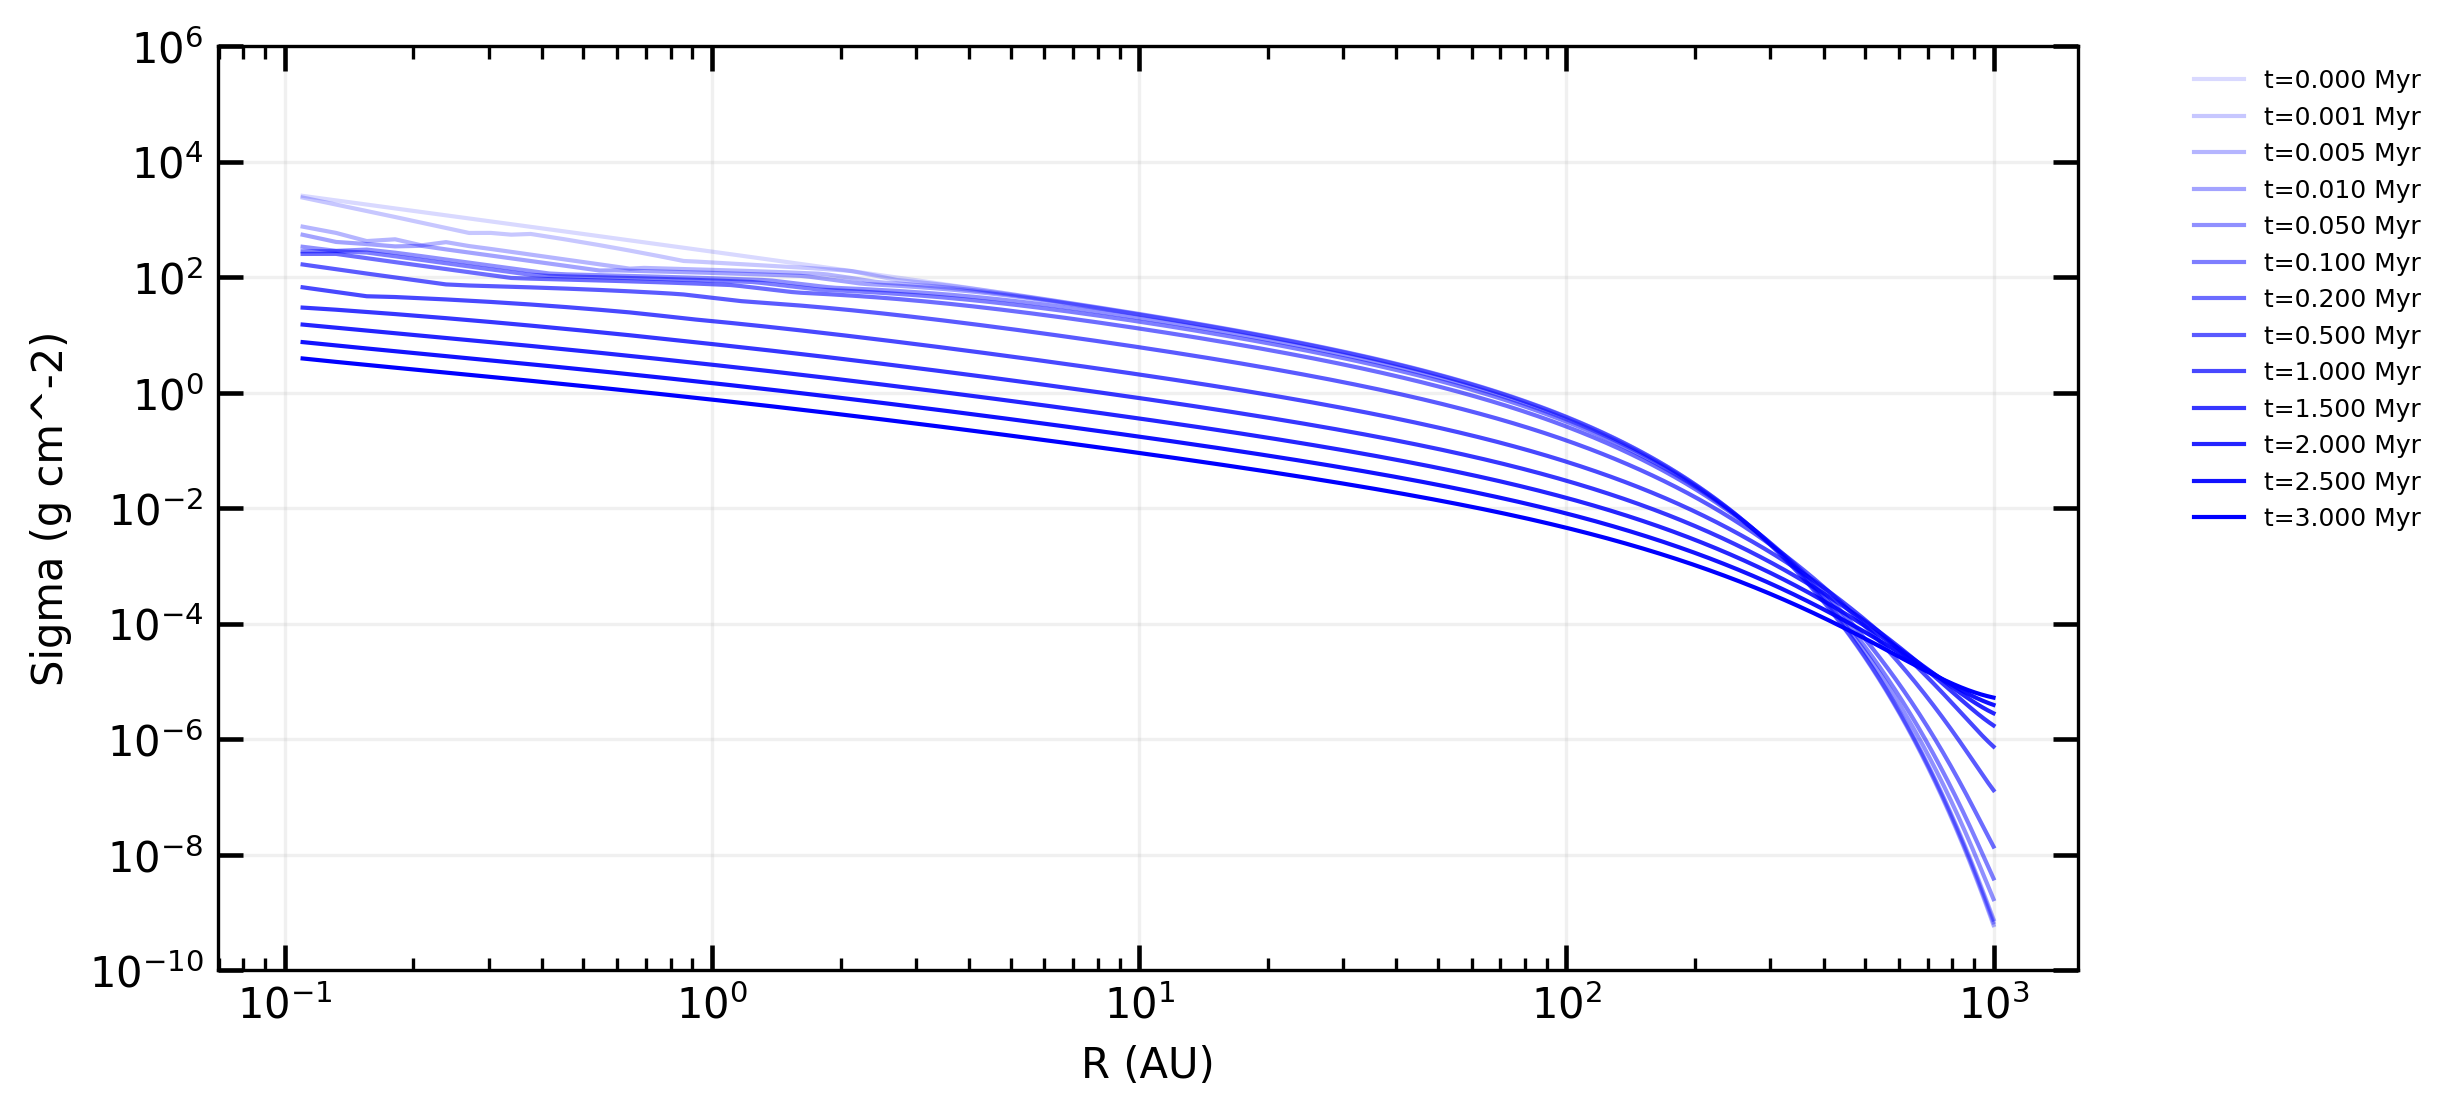

In [22]:
fig, ax = plt.subplots(figsize=(8, 4), dpi = 300)
alphas = np.array(np.linspace(0.15, 1.0, len(Sigma))) # ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.set_xlabel('R (AU)')
ax.set_ylabel('Sigma (g cm^-2)')
#ax.set_xlim(8,10)
ax.set_ylim(1e-10,1e6)

for i in range(len(Sigma)):
    ax.loglog(
        R, Sigma[i],
        color="blue", alpha=alphas[i],
        label=rf"t={tsnap[i]:.3f} Myr", lw=1.0
    )
    # ax.loglog(
    #     R, Sigma[i],
    #     color="red", alpha=alphas[i],
    #     label=rf"t={tsnap[i]:.3f} Myr", lw=1.0, ls = 'dashed'
    # )
    # rdz_at_snap = np.interp(tsnap[i], np.asarray(t) / 1e6, Rdz)
    # ax.axvline(rdz_at_snap, ymax=0.1, color = 'black', ls = 'dotted', alpha = alphas[i])
    # ax.axvline(rdz_at_snap, ymin=0.9, color = 'black', ls = 'dotted', alpha = alphas[i])


ax.legend(frameon=False, fontsize=6, bbox_to_anchor=(1.05, 1.0), loc='upper left')

In [23]:
Sigma = psi

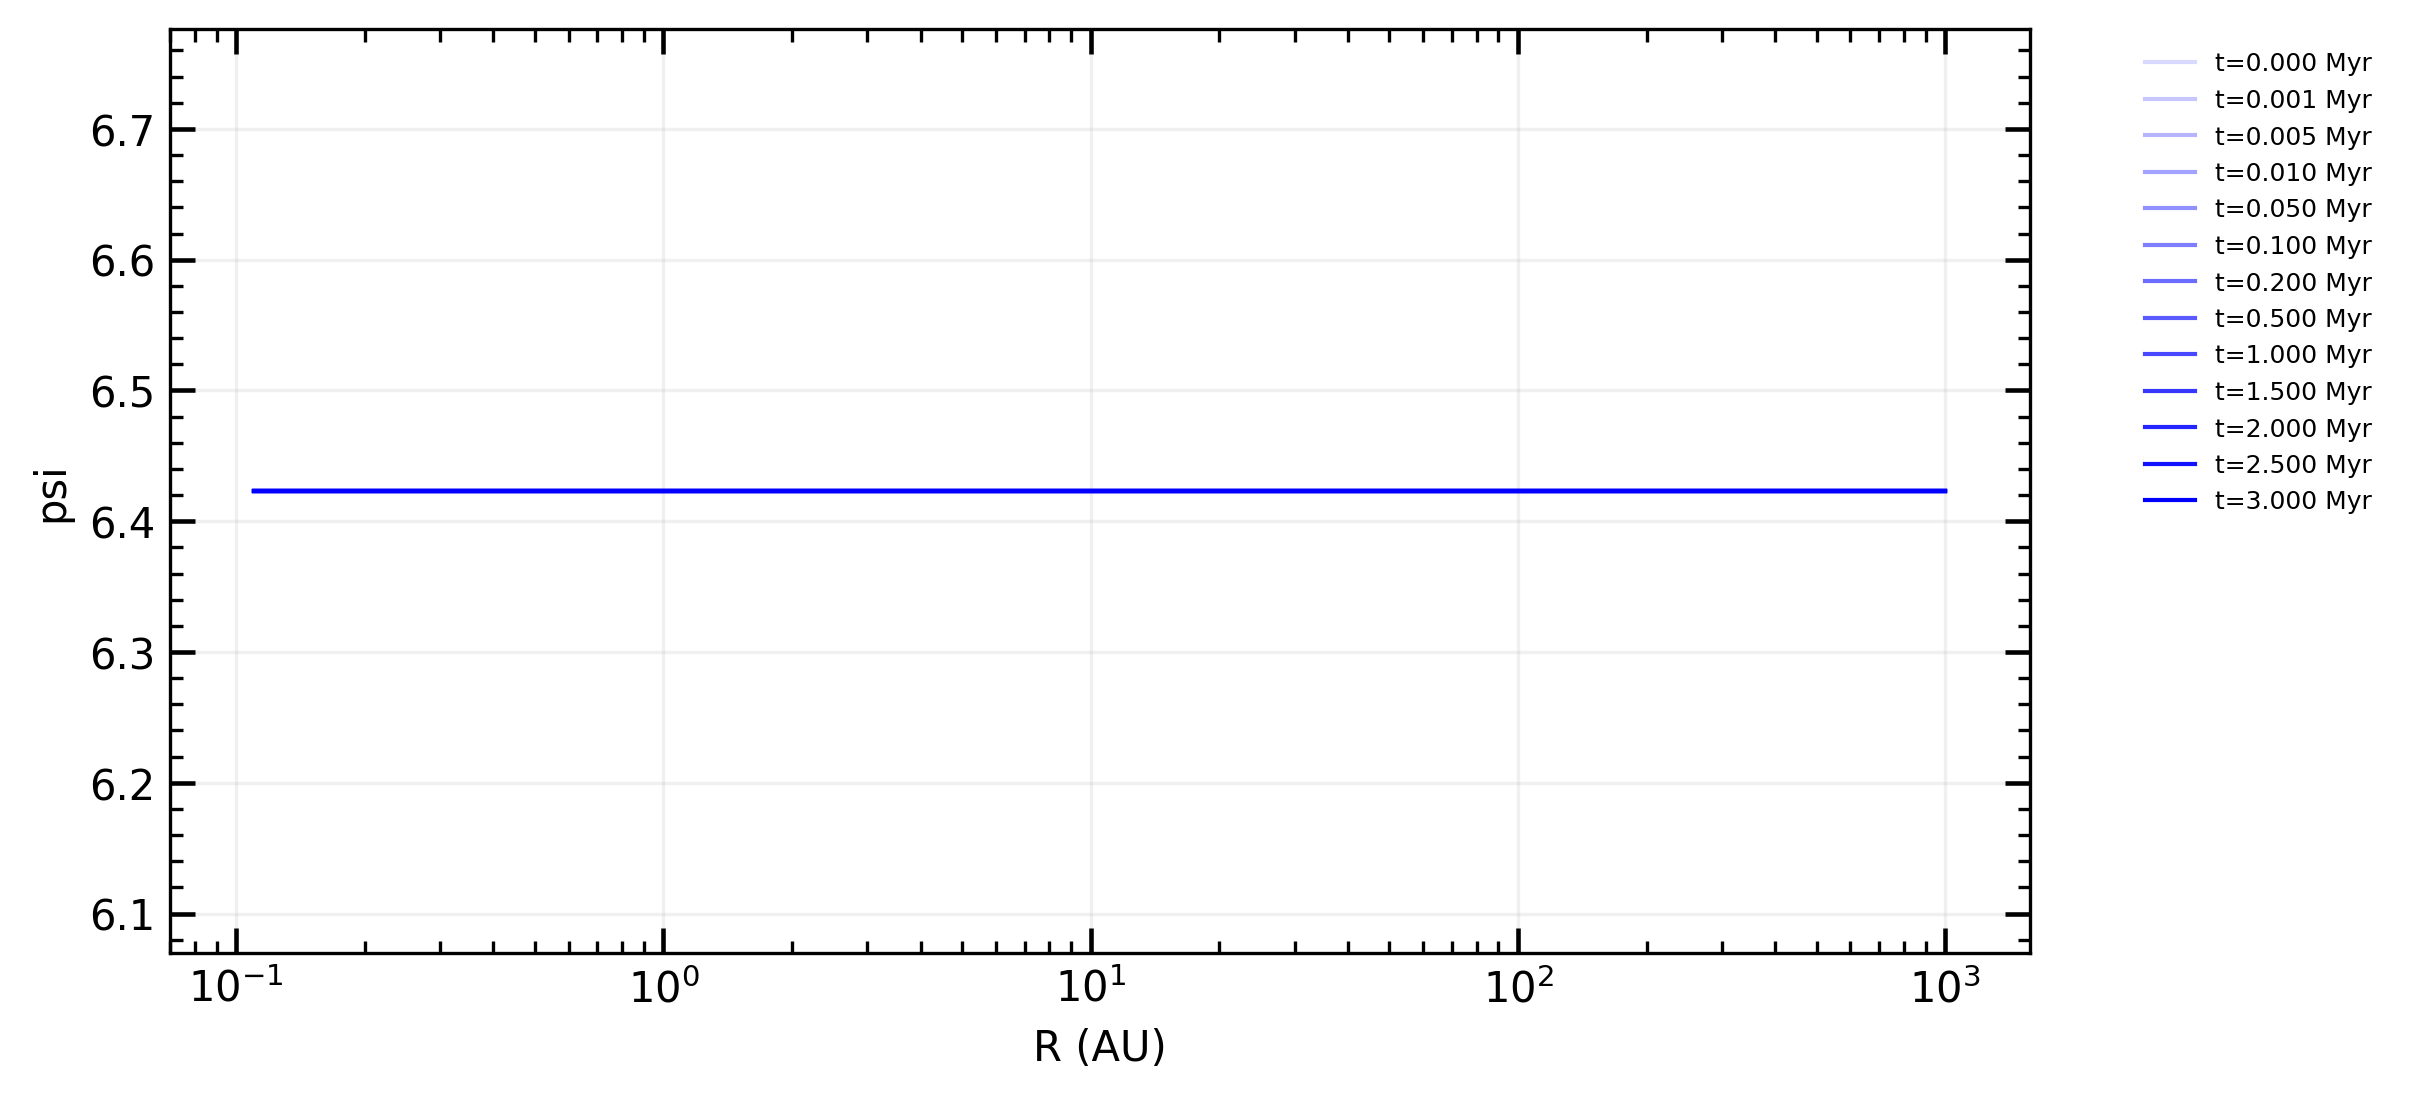

In [28]:
fig, ax = plt.subplots(figsize=(8, 4), dpi = 300)
alphas = np.array(np.linspace(0.15, 1.0, len(Sigma))) # ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.set_xlabel('R (AU)')
ax.set_ylabel('psi')
#ax.set_xlim(8,10)
#ax.set_ylim(1e0,1e2)

for i in range(len(Sigma)):
    ax.semilogx(
        R, Sigma[i],
        color="blue", alpha=alphas[i],
        label=rf"t={tsnap[i]:.3f} Myr", lw=1.0
    )
    # ax.loglog(
    #     R, Sigma[i],
    #     color="red", alpha=alphas[i],
    #     label=rf"t={tsnap[i]:.3f} Myr", lw=1.0, ls = 'dashed'
    # )
    # rdz_at_snap = np.interp(tsnap[i], np.asarray(t) / 1e6, Rdz)
    # ax.axvline(rdz_at_snap, ymax=0.1, color = 'black', ls = 'dotted', alpha = alphas[i])
    # ax.axvline(rdz_at_snap, ymin=0.9, color = 'black', ls = 'dotted', alpha = alphas[i])


ax.legend(frameon=False, fontsize=6, bbox_to_anchor=(1.05, 1.0), loc='upper left')